In [1]:
import pandas as pd
import numpy as np
from pmdarima import auto_arima

In [2]:
Kandi=pd.read_csv("data\Kandi_final.csv")
Parakou=pd.read_csv("data\Parakou_final.csv")

<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_860\3890621831.py:1: SyntaxWarning: invalid escape sequence '\K'
  Kandi=pd.read_csv("data\Kandi_final.csv")
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_860\3890621831.py:2: SyntaxWarning: invalid escape sequence '\P'
  Parakou=pd.read_csv("data\Parakou_final.csv")


In [3]:
Kandi["Pluviometrie"]

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
4012    0.0
4013    0.0
4014    0.0
4015    0.0
4016    0.0
Name: Pluviometrie, Length: 4017, dtype: float64

In [4]:
def changement(x):
    if x<10:
        return f"0{x}"
    else :
        return f"{x}"
Kandi["Date"]=Kandi["annee"].apply(changement)+"-"+Kandi["mois"].apply(changement)+"-"+Kandi["jour"].apply(changement)
Kandi["Date"]=pd.to_datetime(Kandi["Date"])
Kandi=Kandi.set_index("Date")


Parakou["Date"]=Parakou["annee"].apply(changement)+"-"+Parakou["mois"].apply(changement)+"-"+Parakou["jour"].apply(changement)
Parakou["Date"]=pd.to_datetime(Parakou.Date)
Parakou=Parakou.set_index("Date")

In [5]:
Kandi.head()

,Lieu,annee,mois,jour,Pression,Temperature_Max,Temperature_Min,Humidite,Vitesse_Vent,Pluviometrie
Date,,,,,,,,,,
2015-01-01,KANDI_AEROPORT,2015,1,1,979.9,32.0,13.4,32.0,2.4,0.0
2015-01-02,KANDI_AEROPORT,2015,1,2,981.4,30.3,17.4,26.0,2.3,0.0
2015-01-03,KANDI_AEROPORT,2015,1,3,982.8,29.2,17.7,20.0,3.5,0.0
2015-01-04,KANDI_AEROPORT,2015,1,4,983.8,29.0,15.8,20.0,2.8,0.0
2015-01-05,KANDI_AEROPORT,2015,1,5,982.7,29.5,13.5,29.0,3.0,0.0


In [6]:
Kandi_pluie_train=Kandi[Kandi.annee<2024]["Pluviometrie"]
Kandi_pluie_test=Kandi[2024<=Kandi.annee]["Pluviometrie"]

Parakou_pluie_train=Parakou[Parakou.annee<2024]["Pluviometrie"]
Parakou_pluie_test=Parakou[2024<=Parakou.annee]["Pluviometrie"]

Kandi_pluie_train

Date
2015-01-01    0.0
2015-01-02    0.0
2015-01-03    0.0
2015-01-04    0.0
2015-01-05    0.0
             ... 
2023-12-27    0.0
2023-12-28    0.0
2023-12-29    0.0
2023-12-30    0.0
2023-12-31    0.0
Name: Pluviometrie, Length: 3286, dtype: float64

In [7]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
def calcul_erreur_auto(train,test,p,q,m):
    if m==7:
        model=auto_arima(train,seasonal=True,trace=True,start_p=0,start_q=0,max_p=p+1,max_q=q+1,d=0,start_P=0,start_Q=0,max_P=6,max_Q=6,m=m)
        prediction=model.predict(n_periods=len(test))
        return {"Resultats":model,"MAE":mean_absolute_error(test,prediction),"RMSE":np.sqrt(mean_squared_error(test,prediction))}
    else:
        model=auto_arima(train,seasonal=True,trace=True,start_p=0,start_q=0,max_p=p+1,max_q=q+1,d=0,start_P=0,start_Q=0,max_P=3,max_Q=3,m=m)
        prediction=model.predict(n_periods=len(test))
        return {"Resultats":model,"MAE":mean_absolute_error(test,prediction),"RMSE":np.sqrt(mean_squared_error(test,prediction))}


In [8]:
#Calcul_KandiH=calcul_erreur_auto(Kandi_pluie_train,Kandi_pluie_test,6,2,7)

In [9]:
#Calcul_ParakouH=calcul_erreur_auto(Parakou_pluie_train,Parakou_pluie_test,3,1,7)

In [10]:
#Calcul_KandiA=calcul_erreur_auto(Kandi_pluie_train,Kandi_pluie_test,6,2,30)

In [11]:
#Calcul_ParakouA=calcul_erreur_auto(Parakou_pluie_train,Parakou_pluie_test,3,1,30)

In [12]:
#Calcul_KandiH

In [13]:
#Calcul_KandiH["Resultats"].order

In [14]:
"""resultatsH=pd.concat([pd.DataFrame({"Station":["Kandi"],"p ":Calcul_KandiH["Resultats"].order[0],"q ":Calcul_KandiH["Resultats"].order[-1],"P ":Calcul_KandiH["Resultats"].seasonal_order[0],
                                    "Q":Calcul_KandiH["Resultats"].seasonal_order[2],"MAE":Calcul_KandiH["MAE"],"RMSE":Calcul_KandiH["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"p ":Calcul_ParakouH["Resultats"].order[0],"q ":Calcul_ParakouH["Resultats"].order[-1],"P ":Calcul_ParakouH["Resultats"].seasonal_order[0],
                                  "Q":Calcul_ParakouH["Resultats"].seasonal_order[2],"MAE":Calcul_ParakouH["MAE"],"RMSE":Calcul_ParakouH["RMSE"]})],axis=0)

resultatsH"""

'resultatsH=pd.concat([pd.DataFrame({"Station":["Kandi"],"p ":Calcul_KandiH["Resultats"].order[0],"q ":Calcul_KandiH["Resultats"].order[-1],"P ":Calcul_KandiH["Resultats"].seasonal_order[0],\n                                    "Q":Calcul_KandiH["Resultats"].seasonal_order[2],"MAE":Calcul_KandiH["MAE"],"RMSE":Calcul_KandiH["RMSE"]}),\n                    pd.DataFrame({"Station":["Parakou"],"p ":Calcul_ParakouH["Resultats"].order[0],"q ":Calcul_ParakouH["Resultats"].order[-1],"P ":Calcul_ParakouH["Resultats"].seasonal_order[0],\n                                  "Q":Calcul_ParakouH["Resultats"].seasonal_order[2],"MAE":Calcul_ParakouH["MAE"],"RMSE":Calcul_ParakouH["RMSE"]})],axis=0)\n\nresultatsH'

In [15]:
"""resultatsA=pd.concat([pd.DataFrame({"Station":["Kandi"],"p":Calcul_KandiA["Resultats"].order[0],"q":Calcul_KandiA["Resultats"].order[-1],"P":Calcul_KandiA["Resultats"].seasonal_order[0],
                                    "Q":Calcul_KandiA["Resultats"].seasonal_order[2],"MAE":Calcul_KandiA["MAE"],"RMSE":Calcul_KandiA["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"p":Calcul_ParakouA["Resultats"].order[0],"q":Calcul_ParakouA["Resultats"].order[-1],"P":Calcul_ParakouA["Resultats"].seasonal_order[0],
                                  "Q":Calcul_ParakouA["Resultats"].seasonal_order[2],"MAE":Calcul_ParakouA["MAE"],"RMSE":Calcul_ParakouA["RMSE"]})],axis=0)

resultatsA"""

'resultatsA=pd.concat([pd.DataFrame({"Station":["Kandi"],"p":Calcul_KandiA["Resultats"].order[0],"q":Calcul_KandiA["Resultats"].order[-1],"P":Calcul_KandiA["Resultats"].seasonal_order[0],\n                                    "Q":Calcul_KandiA["Resultats"].seasonal_order[2],"MAE":Calcul_KandiA["MAE"],"RMSE":Calcul_KandiA["RMSE"]}),\n                    pd.DataFrame({"Station":["Parakou"],"p":Calcul_ParakouA["Resultats"].order[0],"q":Calcul_ParakouA["Resultats"].order[-1],"P":Calcul_ParakouA["Resultats"].seasonal_order[0],\n                                  "Q":Calcul_ParakouA["Resultats"].seasonal_order[2],"MAE":Calcul_ParakouA["MAE"],"RMSE":Calcul_ParakouA["RMSE"]})],axis=0)\n\nresultatsA'

In [16]:
#resultatsH.to_csv("data/resultats_sarima_semestrielle.csv",index=False)
#resultatsA.to_csv("data/resultats_sarima_Annuel.csv",index=False)

In [ ]:
import matplotlib.pyplot as plt
def calcul_erreur_final(train,test,p,q,P,Q):
    model=auto_arima(train,seasonal=True,trace=True,start_p=p,start_q=q,max_p=p,max_q=q,start_P=P,max_P=P,start_Q=Q,max_Q=Q,d=0,m=7)
    prediction=model.predict(n_periods=len(test))
    plt.figure(figsize=(10,5))
    plt.plot(test.index,test,label="Test")
    plt.plot(test.index,prediction,label="Prediction")
    plt.legend()
    return {"Resultats":model,"MAE":mean_absolute_error(test,prediction),"RMSE":np.sqrt(mean_squared_error(test,prediction))}

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(5,0,2)[7] intercept   : AIC=24019.621, Time=67.54 sec
 ARIMA(0,0,0)(0,0,0)[7] intercept   : AIC=24210.812, Time=0.08 sec
 ARIMA(0,0,0)(1,0,0)[7] intercept   : AIC=24140.982, Time=1.07 sec
 ARIMA(0,0,0)(0,0,1)[7] intercept   : AIC=24154.581, Time=0.68 sec
 ARIMA(0,0,0)(0,0,0)[7]             : AIC=24534.040, Time=0.05 sec
 ARIMA(0,0,0)(4,0,2)[7] intercept   : AIC=24031.969, Time=35.76 sec
 ARIMA(0,0,0)(5,0,1)[7] intercept   : AIC=24020.756, Time=51.14 sec
 ARIMA(0,0,0)(4,0,1)[7] intercept   : AIC=24035.432, Time=26.95 sec
 ARIMA(0,0,0)(5,0,2)[7]             : AIC=24092.879, Time=13.28 sec

Best model:  ARIMA(0,0,0)(5,0,2)[7] intercept
Total fit time: 196.576 seconds


d:\LATEX\Stage\VSCODE Python\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
d:\LATEX\Stage\VSCODE Python\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


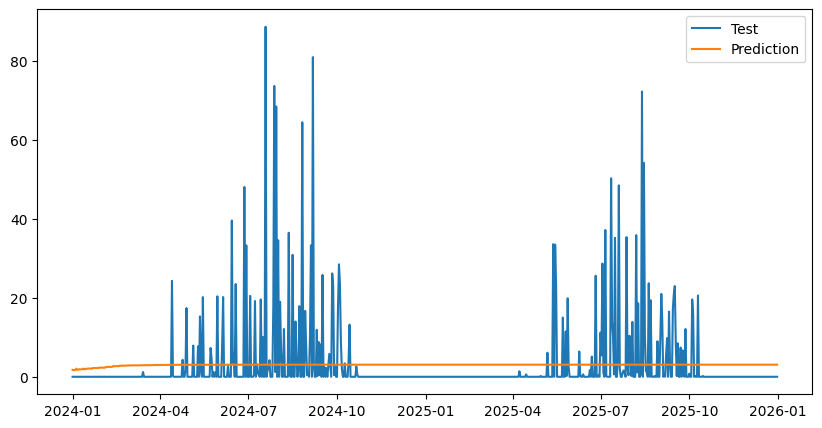

In [18]:
Calcul_KandiF=calcul_erreur_final(Kandi_pluie_train,Kandi_pluie_test,0,0,5,2)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(1,0,1)[7] intercept   : AIC=24035.030, Time=2.21 sec
 ARIMA(0,0,0)(0,0,0)[7] intercept   : AIC=24210.812, Time=0.07 sec
 ARIMA(0,0,0)(1,0,0)[7] intercept   : AIC=24140.982, Time=1.05 sec
 ARIMA(0,0,0)(0,0,1)[7] intercept   : AIC=24154.581, Time=0.77 sec
 ARIMA(0,0,0)(0,0,0)[7]             : AIC=24534.040, Time=0.04 sec
 ARIMA(0,0,0)(1,0,1)[7]             : AIC=24101.640, Time=0.45 sec

Best model:  ARIMA(0,0,0)(1,0,1)[7] intercept
Total fit time: 4.655 seconds


d:\LATEX\Stage\VSCODE Python\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
d:\LATEX\Stage\VSCODE Python\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


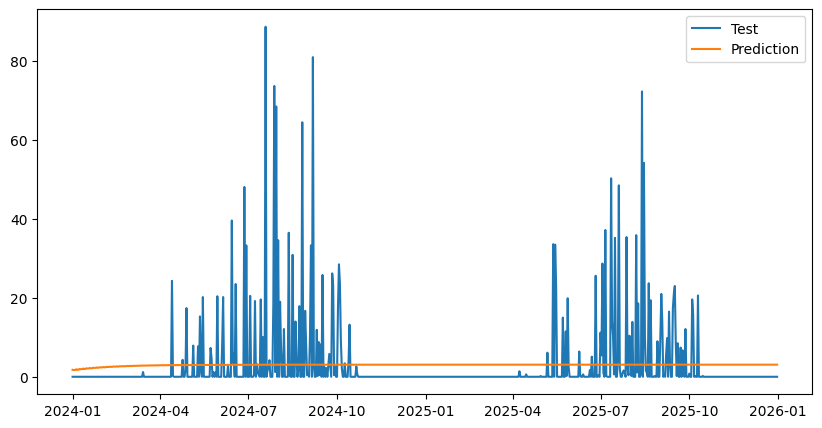

In [19]:
Calcul_ParakouF=calcul_erreur_final(Kandi_pluie_train,Kandi_pluie_test,0,0,1,1)